Теперь меня интересует не только предсказание одной оценки, но и изменение вероятностей при появлении информации. Самостоятельно предложим небольшой граф и оценим его условные распределения по данным. Готовую структуру из примера использовать не будем.


In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_style('whitegrid')


# Загрузка и первичный анализ

Объединим прежние csv-файлы и сохраним тип вина отдельной переменной `wine_type`. В исходных данных также есть кислотности, сахар, хлориды, соединения серы, плотность, pH, сульфаты и алкоголь. Для сети выберу пять переменных, чтобы зависимости и условные таблицы оставались понятными.

| Переменная | Исходное поле | Смысл |
|---|---|---|
| `wine_type` | Тип csv-файла | Белое или красное вино |
| `alcohol` | alcohol | Содержание алкоголя |
| `acidity` | volatile acidity | Летучая кислотность, а не pH и не общая кислотность |
| `density` | density | Плотность вина |
| `quality` | quality | Сенсорная оценка качества |

Предположу, что химические характеристики могут различаться между типами вина, алкоголь связан с плотностью, а сочетание типа вина, алкоголя и летучей кислотности — с оценкой. Это исходные предположения для структуры; направление стрелок ещё не будет доказательством причинности.


In [2]:
root = Path.cwd()
if not (root / 'regression').is_dir():
    root = root.parent
data_dir = root / 'regression' / 'data' / 'wine+quality'

red_wine = pd.read_csv(data_dir / 'winequality-red.csv', sep=';').assign(wine_type='red')
white_wine = pd.read_csv(data_dir / 'winequality-white.csv', sep=';').assign(wine_type='white')
df = pd.concat([red_wine, white_wine], ignore_index=True)

print('Размер датасета:', df.shape)
print('Пропущенных значений:', df.isna().sum().sum())
print('Полные повторы строк:', df.duplicated().sum())
display(df[['alcohol', 'volatile acidity', 'density', 'quality']].describe().round(4))


Размер датасета: (6497, 13)
Пропущенных значений: 0
Полные повторы строк: 1177


,alcohol,volatile acidity,density,quality
count,6497.0000,6497.0000,6497.0000,6497.0000
mean,10.4918,0.3397,0.9947,5.8184
std,1.1927,0.1646,0.0030,0.8733
min,8.0000,0.0800,0.9871,3.0000
25%,9.5000,0.2300,0.9923,5.0000
50%,10.3000,0.2900,0.9949,6.0000
75%,11.3000,0.4000,0.9970,6.0000
max,14.9000,1.5800,1.0390,9.0000


Чтобы одинаковые записи не получали дополнительный вес при оценке вероятностей, удалю полные повторы исходных строк. Это не доказывает, что каждая пара одинаковых записей относится к одному образцу; это выбранное правило подготовки данных. Результаты дальше описывают таблицу без полных повторов, и её частоты могут отличаться от исходных.

Строки, совпадающие только по пяти выбранным переменным, оставляем: они могут различаться по остальным измерениям. Пропусков нет, поэтому заполнение не требуется.


In [3]:
df = df.drop_duplicates().reset_index(drop=True)
print('После удаления полных повторов:', df.shape)


После удаления полных повторов: (5320, 13)


# Дискретизация

Построим дискретную сеть. Возьму простые фиксированные границы, чтобы состояния можно было объяснить без привязки к квантилям конкретной выборки.

| Переменная | Состояния и границы |
|---|---|
| `wine_type` | white, red |
| `alcohol` | low: ≤10; medium: (10, 12]; high: >12 |
| `acidity` | low: ≤0.3; medium: (0.3, 0.5]; high: >0.5 |
| `density` | low: ≤0.995; high: >0.995 |
| `quality` | low: ≤4; medium: 5–6; high: ≥7 |

Это рабочие границы для учебной модели, а не универсальные стандарты качества. Разделение оценок объединяет редкие крайние значения и сохраняет три понятных уровня. Для плотности ограничимся двумя состояниями: подробное деление увеличило бы число условных вероятностей.

У такого преобразования есть цена: объекты рядом с границей становятся разными категориями, а различия внутри интервала теряются. Границы задаём до вероятностных запросов и дальше не подстраиваем под ответы.


In [4]:
states = {
    'wine_type': ['white', 'red'],
    'alcohol': ['low', 'medium', 'high'],
    'acidity': ['low', 'medium', 'high'],
    'density': ['low', 'high'],
    'quality': ['low', 'medium', 'high'],
}
data = df[['wine_type']].copy()
data['alcohol'] = pd.cut(df['alcohol'], [-np.inf, 10, 12, np.inf], labels=states['alcohol'])
data['acidity'] = pd.cut(df['volatile acidity'], [-np.inf, 0.3, 0.5, np.inf], labels=states['acidity'])
data['density'] = pd.cut(df['density'], [-np.inf, 0.995, np.inf], labels=states['density'])
data['quality'] = pd.cut(df['quality'], [-np.inf, 4, 6, np.inf], labels=states['quality'])

display(data.head())


,wine_type,alcohol,acidity,density,quality
0,red,low,high,high,medium
1,red,low,high,high,medium
2,red,low,high,high,medium
3,red,low,low,high,medium
4,red,low,high,high,medium


In [5]:
for node in states:
    counts = data[node].value_counts().reindex(states[node], fill_value=0)
    print(node)
    display(pd.DataFrame({'Количество': counts, 'Доля': counts / len(data)}).round(4))


wine_type


,Количество,Доля
wine_type,,
white,3961,0.7445
red,1359,0.2555


alcohol


,Количество,Доля
alcohol,,
low,2205,0.4145
medium,2372,0.4459
high,743,0.1397


acidity


,Количество,Доля
acidity,,
low,2818,0.5297
medium,1652,0.3105
high,850,0.1598


density


,Количество,Доля
density,,
low,2868,0.5391
high,2452,0.4609


quality


,Количество,Доля
quality,,
low,236,0.0444
medium,4075,0.7660
high,1009,0.1897


После подготовки осталось **5320 наблюдений**. Средние оценки 5–6 встречаются у 4075 образцов (76.6%), высокие — у 1009 (19.0%), низкие — у 236 (4.4%). Категория низкого качества редкая, но объединение оценок ≤4 позволяет не оценивать каждую крайнюю оценку отдельно.

Все выбранные состояния встречаются в данных. Белых вин 3961, красных — 1359; высокий алкоголь встречается у 743 образцов. При разбиении на условные группы наблюдений будет меньше, поэтому отдельно посмотрим на поддержку таблиц сети.

# Вопросы к модели

До построения графа зафиксируем три вопроса:

1. Как изменится вероятность высокой оценки `quality=high`, если известно, что содержание алкоголя выше 12?
2. Как изменится эта вероятность, если дополнительно известно, что летучая кислотность не выше 0.3?
3. Как изменится вероятность высокого содержания алкоголя, если известна низкая плотность вина?

В третьем вопросе информация поступает от измерения плотности к предполагаемому источнику зависимости. Байесовский вывод позволяет обновлять вероятности и против направления стрелки.

Для отдельного эксперимента с evidence последовательно узнаем высокий алкоголь, низкую летучую кислотность и белый тип вина. Интересующая переменная во всех четырёх шагах — `quality`.


# Структура сети

Выберем следующие зависимости:

| Рёбра | Почему предполагается зависимость и выбрано направление |
|---|---|
| `wine_type → alcohol`, `wine_type → acidity`, `wine_type → density` | Тип вина описывает группу с особенностями состава. Поставлю его перед измерениями как известный контекст образца; это не утверждение, что изменение цвета само меняет состав |
| `alcohol → density` | Алкоголь и плотность связаны составом жидкости. Выберу описание плотности через тип и алкоголь, понимая, что сахар и другие вещества здесь не учтены |
| `wine_type → quality` | Позволим распределению оценок различаться между типами даже при одинаковых категориях алкоголя и кислотности. Тип может отражать неучтённые особенности состава и оценки |
| `alcohol → quality`, `acidity → quality` | Оценка связана с измеряемыми свойствами образца. Направлю рёбра от характеристик к оценке как способ описания её условного распределения |

Рёбра заданы по смыслу переменных, а не автоматически по корреляциям. Получился DAG: сначала тип вина, затем алкоголь и кислотность, затем плотность и качество. Обратного пути к предыдущему уровню нет.

Обозначим тип вина через $T$, алкоголь — $A$, кислотность — $V$, плотность — $D$, качество — $Q$. Совместное распределение факторизуется так:

$$P(T,A,V,D,Q)=P(T)P(A\mid T)P(V\mid T)P(D\mid T,A)P(Q\mid T,A,V).$$

Структура задаёт и ограничения: например, алкоголь и кислотность считаются условно независимыми при известном типе. Плотность не даёт дополнительной информации о качестве, если известны тип, алкоголь и кислотность. Это упрощения модели, которые могут выполняться в данных лишь приближённо.


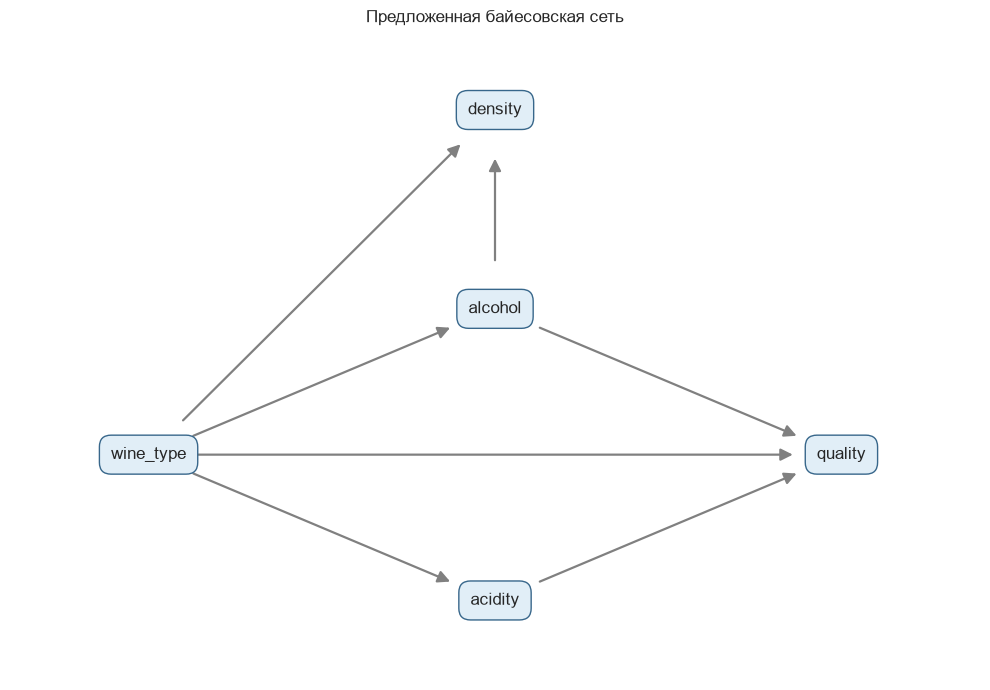

In [6]:
parents = {
    'wine_type': [],
    'alcohol': ['wine_type'],
    'acidity': ['wine_type'],
    'density': ['wine_type', 'alcohol'],
    'quality': ['wine_type', 'alcohol', 'acidity'],
}
positions = {
    'wine_type': (0, 1.2), 'alcohol': (2, 2.3),
    'acidity': (2, 0.1), 'density': (2, 3.8), 'quality': (4, 1.2),
}
fig, ax = plt.subplots(figsize=(10, 7))
for child, given in parents.items():
    for parent in given:
        ax.annotate('', xy=positions[child], xytext=positions[parent],
                    arrowprops=dict(arrowstyle='-|>', color='gray', lw=1.6,
                                    shrinkA=35, shrinkB=35, mutation_scale=18))
for node, (x, y) in positions.items():
    ax.text(x, y, node, ha='center', va='center', fontsize=12,
            bbox=dict(boxstyle='round,pad=0.7', facecolor='#e1eef7', edgecolor='#38678b'))
ax.set(xlim=(-0.8, 4.8), ylim=(-0.5, 4.4), title='Предложенная байесовская сеть')
ax.axis('off')
plt.tight_layout()
plt.show()


# Достаточность наблюдений

Количество строк само по себе не гарантирует точности: важно, сколько наблюдений приходится на каждое сочетание родителей. Посчитаем число условных строк таблиц, минимальную поддержку и количество групп с менее чем 30 наблюдениями. Порог 30 здесь служит ориентиром для описания малых групп, а не гарантией надёжности.

Число свободных вероятностей у узла равно количеству сочетаний родителей, умноженному на число состояний узла минус один. Последняя вероятность в каждой строке определяется условием суммы, равной единице.


In [7]:
support_rows = []
for node, given in parents.items():
    counts = data.groupby(given, observed=False).size() if given else pd.Series([len(data)])
    support_rows.append({
        'Узел': node, 'Условных строк': len(counts),
        'Минимум наблюдений': counts.min(), 'Групп с n < 30': counts.lt(30).sum(),
        'Свободных вероятностей': len(counts) * (len(states[node]) - 1),
    })
support = pd.DataFrame(support_rows).set_index('Узел')
display(support)
print('Всего свободных вероятностей:', support['Свободных вероятностей'].sum())


,Условных строк,Минимум наблюдений,Групп с n < 30,Свободных вероятностей
Узел,,,,
wine_type,1,5320,0,1
alcohol,2,1359,0,4
acidity,2,1359,0,4
density,6,128,0,6
quality,18,18,2,36


Всего свободных вероятностей: 51


В сети **51 свободная вероятность**. Самая подробная таблица — у качества: 18 сочетаний типа, алкоголя и кислотности. Все сочетания представлены, но в двух группах меньше 30 наблюдений.

Минимальная группа содержит только 18 красных вин с высоким алкоголем и низкой летучей кислотностью; другая малая группа — 26 красных вин с низкими алкоголем и кислотностью. Поэтому отдельные вероятности этих групп не следует считать точными только из-за общего размера датасета. У плотности минимальная поддержка условной строки — 128 наблюдений.

# Оценка условных вероятностей

Используем частоты со сглаживанием Лапласа: к каждому состоянию в каждой строке условной таблицы добавим одно псевдонаблюдение.

$$\widehat P(X=x\mid U=u)=\frac{N(x,u)+1}{N(u)+r_X},$$

где $r_X$ — число состояний узла. Это соответствует симметричному априорному распределению Дирихле с параметрами 1. Сглаживание не даёт объявить событие невозможным только потому, что его не встретили в небольшой группе. Оно не заменяет реальные наблюдения и сильнее влияет на малые группы.

Параметры оцениваем по всем подготовленным строкам. Эта работа описывает вероятностные зависимости в выбранном наборе; отдельную оценку предсказательного качества здесь не проводим.


In [8]:
def estimate_cpts(frame, graph):
    tables = {}
    for node, given in graph.items():
        columns = given + [node]
        index = (pd.MultiIndex.from_product([states[c] for c in columns], names=columns)
                 if given else pd.Index(states[node], name=node))
        counts = frame.groupby(columns, observed=True).size().reindex(index, fill_value=0)
        smoothed = counts + 1
        total = smoothed.groupby(level=given).transform('sum') if given else smoothed.sum()
        tables[node] = pd.DataFrame({'Count': counts, 'Probability': smoothed / total})
    return tables


cpts = estimate_cpts(data, parents)


In [9]:
def cpt_table(node):
    return cpts[node]['Probability'].unstack(node).reindex(columns=states[node])


print('P(alcohol | wine_type):')
display(cpt_table('alcohol').round(4))
print('P(density | wine_type, alcohol):')
display(cpt_table('density').round(4))


P(alcohol | wine_type):


alcohol,low,medium,high
wine_type,,,
red,0.4684,0.4369,0.0947
white,0.3958,0.4488,0.1554


P(density | wine_type, alcohol):


density               low    high
wine_type alcohol                
red       high     0.6692  0.3308
          low      0.0250  0.9750
          medium   0.1980  0.8020
white     high     0.9919  0.0081
          low      0.3433  0.6567
          medium   0.8438  0.1562

In [10]:
quality_counts = data.groupby(parents['quality'], observed=False).agg(
    n=('quality', 'size'),
    empirical_high=('quality', lambda values: values.eq('high').mean()),
)
quality_table = cpt_table('quality').join(quality_counts)
display(quality_table.round(4))


low  medium    high     n  empirical_high
wine_type alcohol acidity                                              
red       high    high     0.0435  0.6087  0.3478    43          0.3488
                  low      0.0476  0.4286  0.5238    18          0.5556
                  medium   0.0143  0.4857  0.5000    67          0.5075
          low     high     0.0668  0.9208  0.0124   401          0.0100
                  low      0.0690  0.7586  0.1724    26          0.1538
                  medium   0.0376  0.9155  0.0469   210          0.0429
          medium  high     0.0940  0.8158  0.0902   263          0.0875
                  low      0.0123  0.5926  0.3951    78          0.3974
                  medium   0.0195  0.7656  0.2148   253          0.2134
white     high    high     0.1212  0.5152  0.3636    30          0.3667
                  low      0.0063  0.5175  0.4762   312          0.4776
                  medium   0.0254  0.3841  0.5906   273          0.5934
          low     high     0.2800  0.7067  0.0133    72          0.0000
                  low      0.0363  0.8910  0.0727  1015          0.0719
                  medium   0.0537  0.9298  0.0165   481          0.0146
          medium  high     0.3182  0.6364  0.0455    41          0.0244
                  low      0.0299  0.7194  0.2507  1369          0.2505
                  medium   0.0809  0.7035  0.2156   368          0.2147

Высокий алкоголь встречается у белых вин с вероятностью 0.1554, у красных — 0.0947. Следовательно, заданная зависимость от типа действительно отражает различие частот.

У белых вин вероятность низкой плотности меняется от 0.3433 при низком алкоголе до 0.9919 при высоком; у красных — от 0.0250 до 0.6692. Связь заметна внутри обоих типов, но уровень плотности между ними различается. Это согласуется с выбранными родителями плотности, хотя не объясняет весь состав вина.

В таблице качества столбец `empirical_high` — доля высоких оценок в исходной условной группе. Сглаженная вероятность обычно близка к ней. Например, у белых вин с высоким алкоголем и низкой кислотностью это 0.4776 и 0.4762 при n=312. В малой группе красных вин с теми же категориями разница заметнее: 10 из 18 образцов имеют высокую оценку (0.5556), после сглаживания получается 11/21 = 0.5238.

Необычные случаи тоже важно сохранить. Среди 72 белых вин с низким алкоголем и высокой кислотностью высоких оценок нет. Модель даёт вероятность 1/75 = 0.0133, а не объявляет такой исход невозможным. У белых вин с высоким алкоголем средняя кислотность связана с большей вероятностью высокой оценки (0.5906), чем низкая (0.4762). Значит, правило «меньше кислотность — всегда выше оценка» для этих категорий не выполняется. На различия могут влиять грубые границы и другие свойства образцов внутри групп; причинного объяснения эти частоты не дают.

# Вероятностный вывод

У сети всего 2 × 3 × 3 × 2 × 3 = **108 совместных состояний**. Поэтому точный вывод можно выполнить напрямую: перемножим условные вероятности по факторизации, оставим строки, совместимые с evidence, просуммируем скрытые переменные и нормируем результат. При таком размере приближённый алгоритм не требуется.

Это именно вывод по совместному распределению сети. Он отличается от простого подсчёта доли в отфильтрованной исходной таблице, поскольку использует сглаженные условные распределения и заданные структурой независимости.


In [11]:
def make_joint(tables, graph):
    distribution = pd.DataFrame(product(*states.values()), columns=list(states))
    distribution['probability'] = 1.0
    for node, given in graph.items():
        index = (pd.MultiIndex.from_frame(distribution[given + [node]])
                 if given else distribution[node])
        distribution['probability'] *= tables[node]['Probability'].reindex(index).to_numpy()
    return distribution


joint = make_joint(cpts, parents)


In [12]:
def query(variable, evidence=None, distribution=joint):
    mask = pd.Series(True, index=distribution.index)
    for node, value in (evidence or {}).items():
        mask &= distribution[node].eq(value)
    probabilities = distribution.loc[mask].groupby(variable)['probability'].sum()
    probabilities = probabilities.reindex(states[variable], fill_value=0)
    return probabilities / probabilities.sum()


Сначала сопоставим распределение качества сети с долями в подготовленной таблице. Затем ответим на три вопроса, зафиксированные до построения модели.


In [13]:
prior_comparison = pd.DataFrame({
    'Доля в данных': data['quality'].value_counts(normalize=True).reindex(states['quality']),
    'Вероятность сети': query('quality'),
})
display(prior_comparison.round(4))

query_results = pd.DataFrame({
    'P(quality)': query('quality'),
    'P(quality | alcohol=high)': query('quality', {'alcohol': 'high'}),
    'P(quality | alcohol=high, acidity=low)': query('quality', {'alcohol': 'high', 'acidity': 'low'}),
})
alcohol_results = pd.DataFrame({
    'P(alcohol)': query('alcohol'),
    'P(alcohol | density=low)': query('alcohol', {'density': 'low'}),
})
display(query_results.round(4))
display(alcohol_results.round(4))


,Доля в данных,Вероятность сети
quality,,
low,0.0444,0.0488
medium,0.7660,0.7652
high,0.1897,0.1861


,P(quality),P(quality | alcohol=high),"P(quality | alcohol=high, acidity=low)"
quality,,,
low,0.0488,0.0188,0.0075
medium,0.7652,0.4908,0.5151
high,0.1861,0.4904,0.4775


,P(alcohol),P(alcohol | density=low)
alcohol,,
low,0.4144,0.1932
medium,0.4457,0.5639
high,0.1399,0.2429


Маргинальная вероятность высокой оценки в сети равна **0.1861**, а доля в подготовленных данных — **0.1897**. Небольшое различие ожидаемо: сеть использует сглаживание и заменяет совместное распределение алкоголя и кислотности произведением их условных распределений при известном типе. Модель не обязана точно воспроизводить все исходные частоты.

1. При известном высоком алкоголе вероятность высокой оценки увеличивается с **18.61% до 49.04%**. Эта информация существенно меняет распределение, но высокой оценки всё равно не гарантирует.

2. Добавление низкой кислотности меняет вероятность с **49.04% до 47.75%**. Она остаётся выше исходной, но немного снижается относительно первого запроса. Это согласуется с условными таблицами: у белых вин с высоким алкоголем средняя кислотность связана с более высокой долей хороших оценок, чем низкая. Дополнительная информация не обязана увеличивать вероятность интересующего события.

3. При известной низкой плотности вероятность высокого алкоголя увеличивается с **13.99% до 24.29%**. Вывод идёт против стрелки `alcohol → density`: наблюдение плотности обновляет представление об алкоголе. Одновременно информация проходит через общий контекст `wine_type`, поэтому изменение нельзя приписывать только одному ребру.

# Последовательное добавление evidence

Проследим за всем распределением качества, а не только за вероятностью высокой оценки. На каждом шаге сохраняем предыдущую информацию. Рядом укажем число совместимых исходных наблюдений: это помогает увидеть, насколько узкую группу описывает evidence, но не является доверительным интервалом для вывода сети.


In [14]:
evidence_steps = [
    ('Ничего не известно', {}),
    ('Алкоголь >12', {'alcohol': 'high'}),
    ('+ кислотность ≤0.3', {'alcohol': 'high', 'acidity': 'low'}),
    ('+ белое вино', {'alcohol': 'high', 'acidity': 'low', 'wine_type': 'white'}),
]
evidence_rows = []
for label, evidence in evidence_steps:
    compatible = pd.Series(True, index=data.index)
    for node, value in evidence.items():
        compatible &= data[node].eq(value)
    evidence_rows.append({'Информация': label, **query('quality', evidence).to_dict(),
                          'Наблюдений': compatible.sum()})

evidence_results = pd.DataFrame(evidence_rows).set_index('Информация')
display(evidence_results.round(4))


,low,medium,high,Наблюдений
Информация,,,,
Ничего не известно,0.0488,0.7652,0.1861,5320
Алкоголь >12,0.0188,0.4908,0.4904,743
+ кислотность ≤0.3,0.0075,0.5151,0.4775,330
+ белое вино,0.0063,0.5175,0.4762,312


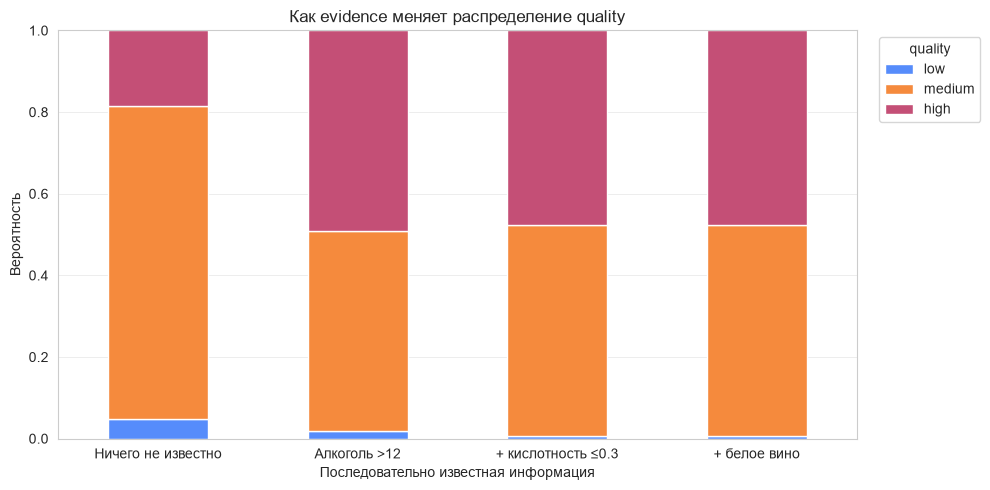

In [15]:
evidence_results[states['quality']].plot.bar(stacked=True, figsize=(10, 5), rot=0)
plt.ylim(0, 1)
plt.xlabel('Последовательно известная информация')
plt.ylabel('Вероятность')
plt.title('Как evidence меняет распределение quality')
plt.legend(title='quality', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


Вероятность высокого качества последовательно меняется так: **18.61% → 49.04% → 47.75% → 47.62%**. Число совместимых наблюдений уменьшается: **5320 → 743 → 330 → 312**.

Первый шаг наиболее заметен: алкоголь — прямой родитель качества. Кислотность тоже входит в его условную таблицу и уточняет распределение при уже известном алкоголе. Последнее условие фиксирует ещё одного родителя — тип вина; после этого распределение качества совпадает с соответствующей строкой CPT для белых вин.

Белый тип меняет результат мало: в данных среди 330 образцов с первыми двумя условиями 312 уже белые. Это согласуется с тем, что последняя информация лишь уточняет состав группы. Вероятности сети при скрытом типе используют собственные веса типов, поэтому этот подсчёт не подменяет байесовский вывод.

В итоге вероятность низкой оценки снижается с 4.88% до 0.63%, средней — с 76.52% до 51.75%. Evidence перераспределяет вероятность между всеми состояниями; больше информации не означает монотонного роста вероятности высокой оценки.

# Изменение структуры

Удалим ребро **alcohol → quality**, сохранив все остальные зависимости и тот же способ сглаживания. Теперь таблица качества оценивает $P(Q\mid T,V)$ вместо $P(Q\mid T,A,V)$. Параметры изменившейся сети нужно оценить заново; просто удалить стрелку на рисунке недостаточно.

Повторим последний запрос: высокая крепость, низкая летучая кислотность, белое вино. При известных типе и кислотности удалённое ребро было единственным оставшимся источником дополнительной информации об оценке от алкоголя. В сокращённой сети `quality` становится условно независимой от `alcohol` при этих условиях.


In [16]:
reduced_parents = {node: given.copy() for node, given in parents.items()}
reduced_parents['quality'].remove('alcohol')
reduced_cpts = estimate_cpts(data, reduced_parents)
reduced_joint = make_joint(reduced_cpts, reduced_parents)

evidence = evidence_steps[-1][1]
structure_comparison = pd.DataFrame({
    'Исходная сеть': query('quality', evidence),
    'Без alcohol → quality': query('quality', evidence, reduced_joint),
})
structure_comparison['Изменение'] = structure_comparison.iloc[:, 1] - structure_comparison.iloc[:, 0]
display(structure_comparison.round(4))


,Исходная сеть,Без alcohol → quality,Изменение
quality,,,
low,0.0063,0.0289,0.0226
medium,0.5175,0.7614,0.2439
high,0.4762,0.2097,-0.2665


После удаления `alcohol → quality` вероятность высокой оценки при тех же условиях снижается с **47.62% до 20.97%**, то есть на **26.65 процентного пункта**. Вероятность средней оценки возрастает с 51.75% до 76.14%.

В исходной сети высокий алкоголь выбирал отдельную строку CPT качества. В сокращённой сети при уже известных типе и кислотности алкоголь больше не уточняет распределение оценки: в таблице смешаны низкий, средний и высокий уровни алкоголя. Поэтому сильное изменение согласуется с удалённой зависимостью.

Структура определяет, какие зависимости допускаются и какие переменные суммируются при выводе. После удаления ребра таблица качества усредняет данные по категориям алкоголя. Поэтому даже на тех же наблюдениях и с тем же evidence получается другое распределение. Одновременно уменьшается число параметров и меняется действие сглаживания; разность нельзя трактовать как чистый причинный эффект алкоголя.

Этот эксперимент показывает чувствительность одного запроса к одному ребру. Он не доказывает, что исходная структура оптимальна.

# Можно ли считать сеть причинной?

Построенную сеть нельзя считать установленной причинной моделью. Данные наблюдаемые, структура предложена вручную, а часть состава и условий оценки не включена. Например, остаточный сахар связан с плотностью, но в сети отсутствует. Тип вина также объединяет много различий, которые мы не можем отделить друг от друга.

В наблюдаемых данных различные DAG могут задавать одинаковые условные независимости. Поэтому направление рёбер нельзя надёжно восстановить только из совместных частот или корреляций. Для причинной интерпретации нужны дополнительные предметные предположения, временной порядок, учёт общих причин или данные о вмешательствах.

Здесь $P(Q\mid A=high)$ — вероятность при наблюдении высокого алкоголя. Она не отвечает на вопрос, что станет с качеством после добавления спирта к тому же вину. Наблюдение и вмешательство — разные задачи.

# Итог

Удалось описать совместное распределение пяти переменных и выполнить точный вероятностный вывод при неполной информации. Наиболее заметны связь высокого алкоголя с качеством и возможность уточнить алкоголь по плотности. Низкая кислотность при уже известном высоком алкоголе не дала дополнительного роста вероятности высокой оценки.

Evidence последовательно меняло всё распределение качества; направление изменений зависело от сочетания условий. Удаление одного ребра изменило вероятность высокой оценки на 26.65 процентного пункта, показав существенную зависимость ответа от выбранной структуры. Эти результаты описывают наблюдаемые связи и не устанавливают эффект вмешательств.

Основные ограничения: ручной выбор графа и границ категорий, потеря информации при дискретизации, малые условные группы, сглаживание и неучтённые характеристики. Полные повторы удалены по выбранному правилу, но это не гарантирует независимость оставшихся образцов. Полученные вероятности относятся к подготовленным данным, а не автоматически ко всем винам.
